# Global Population Analysis     

Population data provides valuable context for understanding how people are distributed across countries and regions. Examining
population size, growth, density, and geographic characteristics can support research, resource planning, and business decisions.This project aims to bring together population and country-level information from three sources: a downloadable CSV dataset, Worldometers web tables, and the REST Countries API. It demonstrates how data in different formats can be collected, cleaned, standardized, and combined into a dataset suitable for exploratory analysis.

### Project Objectives

- Integrate population and geographic data from multiple sources.
- Standardize country names, country codes, column names, and data types.
- Identify missing values, duplicates, and potential outliers.
- Store cleaned datasets in SQLite and combine them using SQL joins.
- Explore population patterns and relationships through visualizations.



### Source 1 — CSV/Excel  (Downloaded from     https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset )

In [554]:
#Necessary library imports

import pandas as pd
import numpy as np
import pycountry
import requests 

In [555]:

# set path
path = "world_population.csv"  

#Load CSV
df_csv = pd.read_csv(path)



In [556]:
df_csv.head()

,Rank,CCA3,Country/Territory,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
0,36,AFG,Afghanistan,Kabul,Asia,41128771,38972230,33753499,28189672,19542982,10694796,12486631,10752971,652230,63.0587,1.0257,0.52
1,138,ALB,Albania,Tirana,Europe,2842321,2866849,2882481,2913399,3182021,3295066,2941651,2324731,28748,98.8702,0.9957,0.04
2,34,DZA,Algeria,Algiers,Africa,44903225,43451666,39543154,35856344,30774621,25518074,18739378,13795915,2381741,18.8531,1.0164,0.56
3,213,ASM,American Samoa,Pago Pago,Oceania,44273,46189,51368,54849,58230,47818,32886,27075,199,222.4774,0.9831,0.00
4,203,AND,Andorra,Andorra la Vella,Europe,79824,77700,71746,71519,66097,53569,35611,19860,468,170.5641,1.0100,0.00


In [557]:
df_csv.columns

Index(['Rank', 'CCA3', 'Country/Territory', 'Capital', 'Continent',
       '2022 Population', '2020 Population', '2015 Population',
       '2010 Population', '2000 Population', '1990 Population',
       '1980 Population', '1970 Population', 'Area (km²)', 'Density (per km²)',
       'Growth Rate', 'World Population Percentage'],
      dtype='object')

In [558]:
df_csv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Rank                         234 non-null    int64  
 1   CCA3                         234 non-null    object 
 2   Country/Territory            234 non-null    object 
 3   Capital                      234 non-null    object 
 4   Continent                    234 non-null    object 
 5   2022 Population              234 non-null    int64  
 6   2020 Population              234 non-null    int64  
 7   2015 Population              234 non-null    int64  
 8   2010 Population              234 non-null    int64  
 9   2000 Population              234 non-null    int64  
 10  1990 Population              234 non-null    int64  
 11  1980 Population              234 non-null    int64  
 12  1970 Population              234 non-null    int64  
 13  Area (km²)          

In [559]:
# Rename to simple names we’ll use later
df_csv = df_csv.rename(columns={
    "CCA3": "ISO3",         #CCA3 stands for Country Code Alpha-3, which is the three-letter ISO 3166-1 code assigned to each country.
    "Country/Territory": "Country",
    "Area (km²)": "Area_km2",
    "Density (per km²)": "Density_per_km2",
    "World Population Percentage": "World_Pct"
})


In [560]:
df_csv.columns

Index(['Rank', 'ISO3', 'Country', 'Capital', 'Continent', '2022 Population',
       '2020 Population', '2015 Population', '2010 Population',
       '2000 Population', '1990 Population', '1980 Population',
       '1970 Population', 'Area_km2', 'Density_per_km2', 'Growth Rate',
       'World_Pct'],
      dtype='object')

In [561]:
# Identify the population year columns 
pop_cols = [c for c in df_csv.columns if "Population" in c and c[:4].isdigit()]
pop_cols  



['2022 Population',
 '2020 Population',
 '2015 Population',
 '2010 Population',
 '2000 Population',
 '1990 Population',
 '1980 Population',
 '1970 Population']

In [562]:
# Keep a small set of “ID” columns + population columns
id_cols = ["ISO3", "Country", "Capital", "Continent", "Area_km2", "Density_per_km2", "Growth Rate", "World_Pct"]
id_cols = [c for c in id_cols if c in df_csv.columns]  # keep only those that exist

df_csv_subset = df_csv[id_cols + pop_cols].copy()

df_csv_subset

,ISO3,Country,Capital,Continent,Area_km2,Density_per_km2,Growth Rate,World_Pct,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population
0,AFG,Afghanistan,Kabul,Asia,652230,63.0587,1.0257,0.52,41128771,38972230,33753499,28189672,19542982,10694796,12486631,10752971
1,ALB,Albania,Tirana,Europe,28748,98.8702,0.9957,0.04,2842321,2866849,2882481,2913399,3182021,3295066,2941651,2324731
2,DZA,Algeria,Algiers,Africa,2381741,18.8531,1.0164,0.56,44903225,43451666,39543154,35856344,30774621,25518074,18739378,13795915
3,ASM,American Samoa,Pago Pago,Oceania,199,222.4774,0.9831,0.00,44273,46189,51368,54849,58230,47818,32886,27075
4,AND,Andorra,Andorra la Vella,Europe,468,170.5641,1.0100,0.00,79824,77700,71746,71519,66097,53569,35611,19860
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
229,WLF,Wallis and Futuna,Mata-Utu,Oceania,142,81.4930,0.9953,0.00,11572,11655,12182,13142,14723,13454,11315,9377
230,ESH,Western Sahara,El Aaiún,Africa,266000,2.1654,1.0184,0.01,575986,556048,491824,413296,270375,178529,116775,76371
231,YEM,Yemen,Sanaa,Asia,527968,63.8232,1.0217,0.42,33696614,32284046,28516545,24743946,18628700,13375121,9204938,6843607
232,ZMB,Zambia,Lusaka,Africa,752612,26.5976,1.0280,0.25,20017675,18927715,16248230,13792086,9891136,7686401,5720438,4281671


In [563]:
# Melt to long format: one row per country-year
df_long = df_csv_subset.melt(
    id_vars=id_cols,
    value_vars=pop_cols,
    var_name="Year_Label",
    value_name="Population_CSV"
)

# Extract numeric Year from "YYYY Population"
df_long["Year"] = df_long["Year_Label"].str.extract(r"^(\d{4})").astype(int)
df_long = df_long.drop(columns=["Year_Label"])

# Convert numeric columns
df_long["Population_CSV"] = pd.to_numeric(df_long["Population_CSV"], errors="coerce")
if "Area_km2" in df_long.columns:
    df_long["Area_km2"] = pd.to_numeric(df_long["Area_km2"], errors="coerce")
if "Density_per_km2" in df_long.columns:
    df_long["Density_per_km2"] = pd.to_numeric(df_long["Density_per_km2"], errors="coerce")
if "Growth Rate" in df_long.columns:
    df_long["Growth Rate"] = pd.to_numeric(df_long["Growth Rate"], errors="coerce")
if "World_Pct" in df_long.columns:
    df_long["World_Pct"] = pd.to_numeric(df_long["World_Pct"], errors="coerce")

#  Keep the last 5 years to target ~1000–1500 rows
years_to_keep = sorted(df_long["Year"].unique())[-5:]
df_long = df_long[df_long["Year"].isin(years_to_keep)].reset_index(drop=True)

print("CSV (long) sample:")
display(df_long.head())
print("CSV (long) shape:", df_long.shape)

CSV (long) sample:


,ISO3,Country,Capital,Continent,Area_km2,Density_per_km2,Growth Rate,World_Pct,Population_CSV,Year
0,AFG,Afghanistan,Kabul,Asia,652230,63.0587,1.0257,0.52,41128771,2022
1,ALB,Albania,Tirana,Europe,28748,98.8702,0.9957,0.04,2842321,2022
2,DZA,Algeria,Algiers,Africa,2381741,18.8531,1.0164,0.56,44903225,2022
3,ASM,American Samoa,Pago Pago,Oceania,199,222.4774,0.9831,0.00,44273,2022
4,AND,Andorra,Andorra la Vella,Europe,468,170.5641,1.0100,0.00,79824,2022


CSV (long) shape: (1170, 10)


In [564]:
df_long.columns

Index(['ISO3', 'Country', 'Capital', 'Continent', 'Area_km2',
       'Density_per_km2', 'Growth Rate', 'World_Pct', 'Population_CSV',
       'Year'],
      dtype='object')

## SOURCE 2 — Website (Worldometers snapshot)

In [565]:
wm_url = "https://www.worldometers.info/world-population/population-by-country/"
tables = pd.read_html(wm_url)
wm = tables[0].copy()
wm.head()



,#,Country (or dependency),Population 2025,Yearly Change,Net Change,Density (P/Km²),Land Area (Km²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
0,1,India,1463865525,0.89%,12929734,492,2973190,"−495,753",1.94,28.8,37.1%,17.78%
1,2,China,1416096094,−0.23%,"−3,225,184",151,9388211,"−268,126",1.02,40.1,67.5%,17.20%
2,3,United States,347275807,0.54%,1849236,38,9147420,1230663,1.62,38.5,82.8%,4.22%
3,4,Indonesia,285721236,0.79%,2233305,158,1811570,"−39,509",2.10,30.4,59.6%,3.47%
4,5,Pakistan,255219554,1.57%,3950390,331,770880,"−1,235,336",3.50,20.6,34.4%,3.10%


In [566]:
wm = wm.rename(columns={
    "Country (or dependency)": "Country",
    "Population (2023)": "Population_2023",
    "Density (P/Km²)": "Density_per_km2_web",
    "Land Area (Km²)": "Land_Area_km2_web",
    "Med. Age": "Median_Age",
    "Urban Pop %": "Urban_Pop_Pct",
    "World Share": "World_Share"
})

wm.columns

Index(['#', 'Country', 'Population 2025', 'Yearly Change', 'Net Change',
       'Density_per_km2_web', 'Land_Area_km2_web', 'Migrants (net)',
       'Fert. Rate', 'Median Age', 'Urban_Pop_Pct', 'World_Share'],
      dtype='object')

In [567]:
# Remove unnecessary columns

df_web = wm.drop(columns=['#', 'Population_2025', 'Yearly_Change', 'Net_Change',
                              'Migrants_net', 'Fertility_Rate', 'Median_Age', 'Urban_Pop_Pct', 'World_Share'],
                     errors='ignore')

In [568]:
df_web.head()

,Country,Population 2025,Yearly Change,Net Change,Density_per_km2_web,Land_Area_km2_web,Migrants (net),Fert. Rate,Median Age
0,India,1463865525,0.89%,12929734,492,2973190,"−495,753",1.94,28.8
1,China,1416096094,−0.23%,"−3,225,184",151,9388211,"−268,126",1.02,40.1
2,United States,347275807,0.54%,1849236,38,9147420,1230663,1.62,38.5
3,Indonesia,285721236,0.79%,2233305,158,1811570,"−39,509",2.10,30.4
4,Pakistan,255219554,1.57%,3950390,331,770880,"−1,235,336",3.50,20.6


In [569]:
# Clean number like columns- string to numeric
if "Population_2023" in wm.columns:
    df_web["Population_2023"] = pd.to_numeric(df_web["Population_2023"].astype(str).str.replace(",", ""), errors="coerce")
if "Density_per_km2_web" in wm.columns:
    df_web["Density_per_km2_web"] = pd.to_numeric(df_web["Density_per_km2_web"].astype(str).str.replace(",", ""), errors="coerce")
if "Land_Area_km2_web" in wm.columns:
    df_web["Land_Area_km2_web"] = pd.to_numeric(df_web["Land_Area_km2_web"].astype(str).str.replace(",", ""), errors="coerce")
if "Median_Age" in wm.columns:
    df_web["Median_Age"] = pd.to_numeric(df_web["Median_Age"], errors="coerce")


df_web.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 233 entries, 0 to 232
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Country              233 non-null    object 
 1   Population 2025      233 non-null    int64  
 2   Yearly Change        233 non-null    object 
 3   Net Change           233 non-null    object 
 4   Density_per_km2_web  233 non-null    int64  
 5   Land_Area_km2_web    233 non-null    int64  
 6   Migrants (net)       233 non-null    object 
 7   Fert. Rate           233 non-null    float64
 8   Median Age           233 non-null    float64
dtypes: float64(2), int64(3), object(4)
memory usage: 16.5+ KB


### Define a safe lookup function to map ISO3 , website does not give CCA3, to merge both datasets later, we need a common key. ISO3 is that link

In [570]:
# Define a safe lookup function to map ISO3 

def get_iso3(country_name):
    try:
        return pycountry.countries.lookup(country_name).alpha_3
    except LookupError:
        return None

# Apply the safe lookup
df_web["ISO3"] = df_web["Country"].apply(lambda x: get_iso3(x) if pd.notna(x) else None)

In [571]:
df_web.head()

,Country,Population 2025,Yearly Change,Net Change,Density_per_km2_web,Land_Area_km2_web,Migrants (net),Fert. Rate,Median Age,ISO3
0,India,1463865525,0.89%,12929734,492,2973190,"−495,753",1.94,28.8,IND
1,China,1416096094,−0.23%,"−3,225,184",151,9388211,"−268,126",1.02,40.1,CHN
2,United States,347275807,0.54%,1849236,38,9147420,1230663,1.62,38.5,USA
3,Indonesia,285721236,0.79%,2233305,158,1811570,"−39,509",2.10,30.4,IDN
4,Pakistan,255219554,1.57%,3950390,331,770880,"−1,235,336",3.50,20.6,PAK


### Source 3 — REST Countries API (region, subregion, area, capital)  
#### We can access API through https://restcountries.com/v3.1/all  

In [572]:
# Preferred endpoint with explicit fields (keeps payload small and avoids 400s)
BASE = "https://restcountries.com/v3.1/all"
FIELDS = "cca3,name,region,subregion,population,area,capital"
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; data-class-project/1.0)"}

# Try with params + headers first
try:
    resp = requests.get(BASE, params={"fields": FIELDS}, headers=HEADERS, timeout=60)
    if resp.status_code == 400:
        # Fallback: put fields directly in the URL (some gateways prefer this)
        resp = requests.get(f"{BASE}?fields={FIELDS}", headers=HEADERS, timeout=60)
    resp.raise_for_status()
except requests.HTTPError as e:
    print("HTTP error:", e, "| status:", getattr(resp, "status_code", None))
    raise
except Exception as e:
    print("Request failed:", e)
    raise

data = resp.json()

# Normalize into a DataFrame
df_api = pd.json_normalize(data)

In [573]:
df_api.head()

,cca3,capital,region,subregion,area,population,name.common,name.official,name.nativeName.eng.official,name.nativeName.eng.common,...,name.nativeName.ind.official,name.nativeName.ind.common,name.nativeName.fil.official,name.nativeName.fil.common,name.nativeName.hun.official,name.nativeName.hun.common,name.nativeName.nep.official,name.nativeName.nep.common,name.nativeName.khm.official,name.nativeName.khm.common
0,ATG,[Saint John's],Americas,Caribbean,442.0,103603,Antigua and Barbuda,Antigua and Barbuda,Antigua and Barbuda,Antigua and Barbuda,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BTN,[Thimphu],Asia,Southern Asia,38394.0,784043,Bhutan,Kingdom of Bhutan,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ITA,[Rome],Europe,Southern Europe,301336.0,58927633,Italy,Italian Republic,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TUV,[Funafuti],Oceania,Polynesia,26.0,10643,Tuvalu,Tuvalu,Tuvalu,Tuvalu,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AIA,[The Valley],Americas,Caribbean,91.0,16010,Anguilla,Anguilla,Anguilla,Anguilla,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [574]:
df_api.columns

Index(['cca3', 'capital', 'region', 'subregion', 'area', 'population',
       'name.common', 'name.official', 'name.nativeName.eng.official',
       'name.nativeName.eng.common',
       ...
       'name.nativeName.ind.official', 'name.nativeName.ind.common',
       'name.nativeName.fil.official', 'name.nativeName.fil.common',
       'name.nativeName.hun.official', 'name.nativeName.hun.common',
       'name.nativeName.nep.official', 'name.nativeName.nep.common',
       'name.nativeName.khm.official', 'name.nativeName.khm.common'],
      dtype='object', length=314)

In [575]:
# Keep relevant columns only
df_api_clean = df_api[['cca3', 'name.common', 'capital', 'region', 'subregion', 'area', 'population']].copy()

# Rename columns for consistency
df_api_clean.rename(columns={
    'cca3': 'ISO3',
    'name.common': 'Country',
    'area': 'Area_km2_api',
    'population': 'Population_api'
}, inplace=True)

print("API data sample:")
display(df_api_clean.head())
print("Shape:", df_api_clean.shape)

API data sample:


,ISO3,Country,capital,region,subregion,Area_km2_api,Population_api
0,ATG,Antigua and Barbuda,[Saint John's],Americas,Caribbean,442.0,103603
1,BTN,Bhutan,[Thimphu],Asia,Southern Asia,38394.0,784043
2,ITA,Italy,[Rome],Europe,Southern Europe,301336.0,58927633
3,TUV,Tuvalu,[Funafuti],Oceania,Polynesia,26.0,10643
4,AIA,Anguilla,[The Valley],Americas,Caribbean,91.0,16010


Shape: (250, 7)


In [576]:
df_api_clean.columns

Index(['ISO3', 'Country', 'capital', 'region', 'subregion', 'Area_km2_api',
       'Population_api'],
      dtype='object')

In [577]:
# Convert capital lists to simple strings
df_api_clean['capital'] = df_api_clean['capital'].apply(lambda x: x[0] if isinstance(x, list) and len(x) > 0 else None)

print("API sample:")
display(df_api_clean.head())


API sample:


,ISO3,Country,capital,region,subregion,Area_km2_api,Population_api
0,ATG,Antigua and Barbuda,Saint John's,Americas,Caribbean,442.0,103603
1,BTN,Bhutan,Thimphu,Asia,Southern Asia,38394.0,784043
2,ITA,Italy,Rome,Europe,Southern Europe,301336.0,58927633
3,TUV,Tuvalu,Funafuti,Oceania,Polynesia,26.0,10643
4,AIA,Anguilla,The Valley,Americas,Caribbean,91.0,16010


## Relationship Between the Three Sources

#### All datasets can be merged using the ISO3 (3-letter country code) as a unique key, this ensures a one-to-one relationship between countries across sources:

In [578]:
# Merge 3 sources on ISO3
merged_df = (
    df_csv.merge(df_web, on='ISO3', how='inner')
          .merge(df_api_clean, on='ISO3', how='inner')
)

# Show result
print("Final merged dataset:")
display(merged_df.head())
print("Merged shape:", merged_df.shape)


Final merged dataset:


,Rank,ISO3,Country_x,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,...,Land_Area_km2_web,Migrants (net),Fert. Rate,Median Age,Country,capital,region,subregion,Area_km2_api,Population_api
0,36,AFG,Afghanistan,Kabul,Asia,41128771,38972230,33753499,28189672,19542982,...,652860,"−74,404",4.66,17.3,Afghanistan,Kabul,Asia,Southern Asia,652230.0,43844000
1,138,ALB,Albania,Tirana,Europe,2842321,2866849,2882481,2913399,3182021,...,27400,"−24,230",1.33,37.3,Albania,Tirana,Europe,Southeast Europe,28748.0,2363314
2,34,DZA,Algeria,Algiers,Africa,44903225,43451666,39543154,35856344,30774621,...,2381740,"−27,531",2.67,28.6,Algeria,Algiers,Africa,Northern Africa,2381741.0,47400000
3,213,ASM,American Samoa,Pago Pago,Oceania,44273,46189,51368,54849,58230,...,200,"−1,051",2.25,29.0,American Samoa,Pago Pago,Oceania,Polynesia,199.0,49710
4,203,AND,Andorra,Andorra la Vella,Europe,79824,77700,71746,71519,66097,...,470,843,1.10,43.9,Andorra,Andorra la Vella,Europe,Southern Europe,468.0,88406


Merged shape: (211, 32)


# Term Project- Milestone 2   Flat file exploration and cleaing

In [579]:
#print(merged_df.shape)


In [580]:
df_long.shape

(1170, 10)

In [581]:
#Null value check
display(df_long.isna().sum())


ISO3               0
Country            0
Capital            0
Continent          0
Area_km2           0
Density_per_km2    0
Growth Rate        0
World_Pct          0
Population_CSV     0
Year               0
dtype: int64

In [582]:
#Datatypes
print(df_long.dtypes)

ISO3                object
Country             object
Capital             object
Continent           object
Area_km2             int64
Density_per_km2    float64
Growth Rate        float64
World_Pct          float64
Population_CSV       int64
Year                 int32
dtype: object


### Step #1 — Standardize column names

In [583]:
# Column name cleanup
df = df_long.copy()

# basic normalize
cols = (df.columns
          .str.strip()    # remove whitespace around names
          .str.lower()     # make all lowercase
          .str.replace(r"[^\w]+", "_", regex=True)       # replace any non-word char with '_'
          .str.strip("_"))                               # clean up any underscores



# or use
# df.columns = df.columns.map(lambda x: x.strip().lower().replace(" ", "_").replace("-", "_"))




# ensure uniqueness after cleaning
seen = {}
new_cols = []
for c in cols:
    if c not in seen:
        seen[c] = 0
        new_cols.append(c)
    else:
        seen[c] += 1
        new_cols.append(f"{c}_{seen[c]}")
df.columns = new_cols

print(df_long.columns)
print("============================================================================================")
print(df.columns)


Index(['ISO3', 'Country', 'Capital', 'Continent', 'Area_km2',
       'Density_per_km2', 'Growth Rate', 'World_Pct', 'Population_CSV',
       'Year'],
      dtype='object')
Index(['iso3', 'country', 'capital', 'continent', 'area_km2',
       'density_per_km2', 'growth_rate', 'world_pct', 'population_csv',
       'year'],
      dtype='object')


### Step #2: Trim whitespace & fix casing in string columns

In [584]:
# columns that store text (dtype == object)
obj_cols = df.select_dtypes(include="object").columns

# Remove extra spaces around values 
for c in obj_cols:
    df[c] = df[c].astype(str).str.strip()          # ensures even non-string objects can be cleaned
                                                 

### step #3: Fix casing or inconsistent values

In [585]:
#select object columns
obj_cols = df.select_dtypes(include="object").columns

obj_cols

Index(['iso3', 'country', 'capital', 'continent'], dtype='object')

In [586]:
# Remove extra leading and trailing spaces from all string columns
for c in obj_cols:
    df[c] = df[c].astype(str).str.strip()

# check the first 10 values of 'country' column
print(df['country'].head(10))

0            Afghanistan
1                Albania
2                Algeria
3         American Samoa
4                Andorra
5                 Angola
6               Anguilla
7    Antigua and Barbuda
8              Argentina
9                Armenia
Name: country, dtype: object


In [587]:
# Fix country and capital names (make them Title Case)
for c in obj_cols:
    if any(word in c for word in ["country", "capital"]):
        df[c] = df[c].str.title()

# Show only first 20 rows for selected columns
cols_to_show = ["country", "capital"]
print("First 20 cleaned values from selected columns:\n")
print(df[cols_to_show].head(20).to_string(index=False))

First 20 cleaned values from selected columns:

            country          capital
        Afghanistan            Kabul
            Albania           Tirana
            Algeria          Algiers
     American Samoa        Pago Pago
            Andorra Andorra La Vella
             Angola           Luanda
           Anguilla       The Valley
Antigua And Barbuda     Saint John’S
          Argentina     Buenos Aires
            Armenia          Yerevan
              Aruba       Oranjestad
          Australia         Canberra
            Austria           Vienna
         Azerbaijan             Baku
            Bahamas           Nassau
            Bahrain           Manama
         Bangladesh            Dhaka
           Barbados       Bridgetown
            Belarus            Minsk
            Belgium         Brussels


### Step #4 — Deduplicate rows 

In [588]:
# De-duplication
df = df.drop_duplicates()



### Step #5 — Handle missing values (explicit policy)

In [589]:
df.isna().sum()

iso3               0
country            0
capital            0
continent          0
area_km2           0
density_per_km2    0
growth_rate        0
world_pct          0
population_csv     0
year               0
dtype: int64

In [590]:
# Identify which columns are numeric and which are text
num_cols = df.select_dtypes(include=[np.number]).columns
obj_cols = df.select_dtypes(include="object").columns



In [591]:
import numpy as np
# Fill missing text values with a clear placeholder
for c in obj_cols:
    df[c] = df[c].replace("nan", np.nan)   # convert "nan" strings to real NaN
    df[c] = df[c].fillna("Missing")        # replace NaN with the word 'Missing'

# Check if 'Missing' placeholders were added
print("\nNumber of 'Missing' entries in each text column:")
for c in obj_cols:
    missing_count = (df[c] == "Missing").sum()
    print(f"{c}: {missing_count}")

# Check if any real NaNs remain
print("\nRemaining NaN values after filling:")
print(df[obj_cols].isna().sum())




Number of 'Missing' entries in each text column:
iso3: 0
country: 0
capital: 0
continent: 0

Remaining NaN values after filling:
iso3         0
country      0
capital      0
continent    0
dtype: int64


### Step #6 — Outlier detection & winsorization (IQR rule)

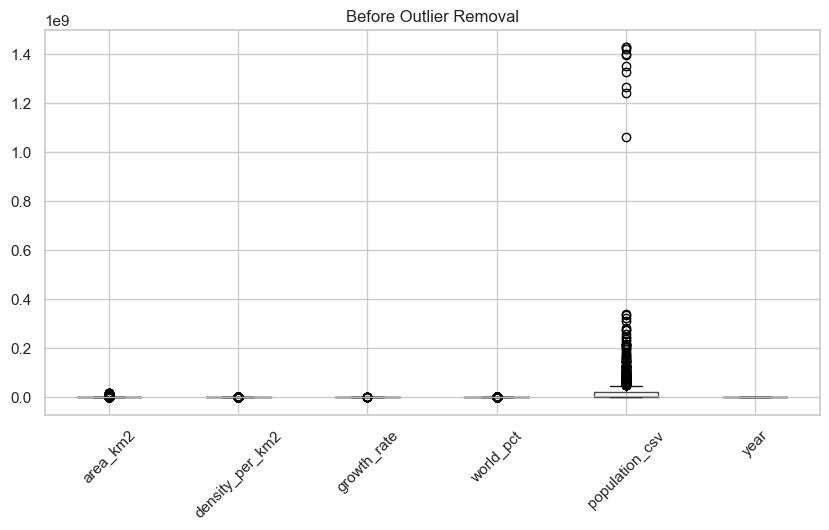

In [592]:
import matplotlib.pyplot as plt

# Visualize BEFORE outlier removal
plt.figure(figsize=(10, 5))
df[num_cols].boxplot()
plt.title("Before Outlier Removal")
plt.xticks(rotation=45)
plt.show()

In [593]:
#Outlier removal
for c in num_cols:
    # Calculate Q1 (25th percentile) and Q3 (75th percentile)
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1

    # Define lower and upper limits
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    
    # Remove rows with outliers for this column
    df = df[(df[c] >= lower_limit) & (df[c] <= upper_limit)]

print("\n Outliers removed using IQR method.")
print(f"Remaining rows after cleaning: {len(df)}")


 Outliers removed using IQR method.
Remaining rows after cleaning: 764


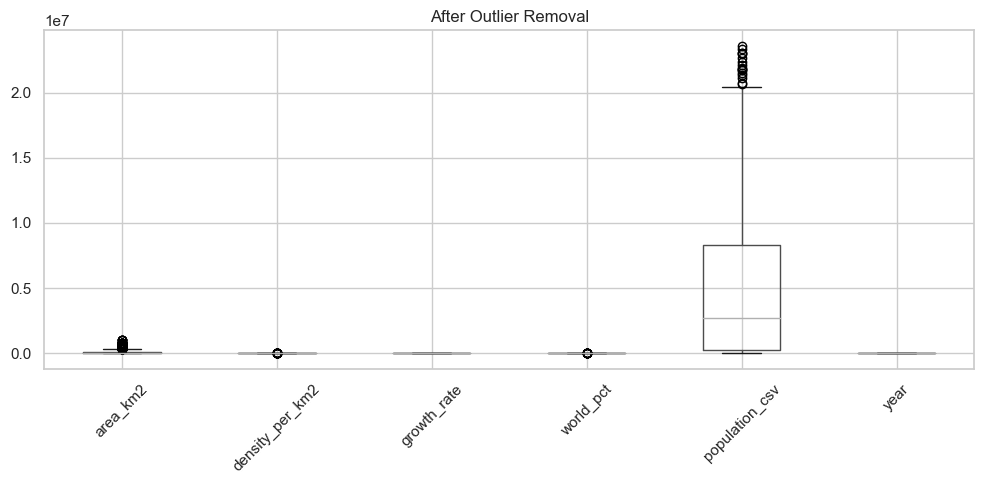

In [594]:

# Visualize AFTER outlier removal
plt.figure(figsize=(10, 5))
df[num_cols].boxplot()
plt.title("After Outlier Removal")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [595]:
print("Final Cleaned Dataset (First 20 rows):")
display(df.head(20))


Final Cleaned Dataset (First 20 rows):


,iso3,country,capital,continent,area_km2,density_per_km2,growth_rate,world_pct,population_csv,year
1,ALB,Albania,Tirana,Europe,28748,98.8702,0.9957,0.04,2842321,2022
3,ASM,American Samoa,Pago Pago,Oceania,199,222.4774,0.9831,0.00,44273,2022
4,AND,Andorra,Andorra La Vella,Europe,468,170.5641,1.0100,0.00,79824,2022
6,AIA,Anguilla,The Valley,North America,91,174.2527,1.0066,0.00,15857,2022
7,ATG,Antigua And Barbuda,Saint John’S,North America,442,212.1335,1.0058,0.00,93763,2022
9,ARM,Armenia,Yerevan,Asia,29743,93.4831,0.9962,0.03,2780469,2022
12,AUT,Austria,Vienna,Europe,83871,106.5877,1.0020,0.11,8939617,2022
13,AZE,Azerbaijan,Baku,Asia,86600,119.6082,1.0044,0.13,10358074,2022
14,BHS,Bahamas,Nassau,North America,13943,29.4043,1.0051,0.01,409984,2022
18,BLR,Belarus,Minsk,Europe,207600,45.9295,0.9955,0.12,9534954,2022


In [596]:
print("\nDataset shape after all transformations:", df.shape)


Dataset shape after all transformations: (764, 10)


In [597]:
df_flat = df.copy()
df_flat.head()

,iso3,country,capital,continent,area_km2,density_per_km2,growth_rate,world_pct,population_csv,year
1,ALB,Albania,Tirana,Europe,28748,98.8702,0.9957,0.04,2842321,2022
3,ASM,American Samoa,Pago Pago,Oceania,199,222.4774,0.9831,0.00,44273,2022
4,AND,Andorra,Andorra La Vella,Europe,468,170.5641,1.0100,0.00,79824,2022
6,AIA,Anguilla,The Valley,North America,91,174.2527,1.0066,0.00,15857,2022
7,ATG,Antigua And Barbuda,Saint John’S,North America,442,212.1335,1.0058,0.00,93763,2022


In [598]:
df.to_csv("population_data.csv", index=False)


## Ethical Implications of Data Wrangling

During this data wrangling project, several transformations were applied, including column header standardization, trimming extra spaces, fixing inconsistent casing, handling missing values, removing duplicates, and addressing outliers using the IQR method. These steps improved data quality, readability, and usability for 
future analysis.
The data came from public sources like Wikipedia and World Bank, so there are no privacy or legal issues. I made some simple assumptions, such as replacing missing text with “Missing” and filling missing numbers with median values. These changes help keep the data consistent, but they may slightly change how some results look.
There is little ethical risk since the dataset does not include any personal or sensitive information. I made sure not to change data in a way that could mislead results. To stay ethical, I used only verified public data and explained all changes clearly so the cleaning process is transparent.

# Term1 - Milestone 3
## Cleaning/Formatting Website Data

In [599]:
##df=pd.read_csv("population_data.csv")
#df.head()

In [600]:
df_web.shape

(233, 10)

In [601]:
df=df_web.copy()

### Text formationg- Non ASCII

In [602]:
# Check for non-ASCII characters

text_cols = df.select_dtypes(include='object').columns

for col in text_cols:
    bad = df[df[col].str.contains(r'[^\x00-\x7F]', na=False)]
    if len(bad):
        print(f"\n Column '{col}' has {len(bad)} non-ASCII entries:")
        display(bad[[col]].head())



 Column 'Country' has 3 non-ASCII entries:


,Country
49,Côte d'Ivoire
162,Réunion
188,Curaçao



 Column 'Yearly Change' has 62 non-ASCII entries:


,Yearly Change
1,−0.23%
8,−0.57%
11,−0.52%
18,−0.56%
19,−0.07%



 Column 'Net Change' has 62 non-ASCII entries:


,Net Change
1,"−3,225,184"
8,"−823,030"
11,"−649,562"
18,"−477,167"
19,"−48,148"



 Column 'Migrants (net)' has 138 non-ASCII entries:


,Migrants (net)
0,"−495,753"
1,"−268,126"
3,"−39,509"
4,"−1,235,336"
5,"−15,258"


In [603]:
# Clean all text columns by re-encoding to ASCII
text_cols = df.select_dtypes(include='object').columns

for col in text_cols:
    df[col] = df[col].astype(str).apply(
        lambda x: x.encode('ascii', 'ignore').decode('ascii')
    )

In [604]:
mask = df.applymap(lambda x: not str(x).isascii())
remaining = mask.any(axis=1).sum()

print(f" Remaining rows with non-ASCII characters: {remaining}")

 Remaining rows with non-ASCII characters: 0


### The above code first scans all text columns to detect and display any cells containing non-ASCII characters (such as accented letters or symbols outside the standard English range). It then cleans those text columns by re-encoding them to ASCII (removing non-ASCII characters)

### Statndardize headers

In [605]:
df.columns

Index(['Country', 'Population 2025', 'Yearly Change', 'Net Change',
       'Density_per_km2_web', 'Land_Area_km2_web', 'Migrants (net)',
       'Fert. Rate', 'Median Age', 'ISO3'],
      dtype='object')

In [606]:
# header cleanup using only string methods
df.columns = (
    df.columns
      .str.strip()               # remove leading/trailing spaces
      .str.lower()               # make lowercase
      .str.replace(" ", "_")     # spaces → underscores
      .str.replace("-", "_")     # hyphens → underscores
)

print("Cleaned headers:")
print(list(df.columns))


Cleaned headers:
['country', 'population_2025', 'yearly_change', 'net_change', 'density_per_km2_web', 'land_area_km2_web', 'migrants_(net)', 'fert._rate', 'median_age', 'iso3']


In [607]:
# swap year-first population headers to a consistent population_YYYY form
fixed_cols = []
for c in df.columns:
    s = str(c)
    if s.endswith("_population"):
        # try to read first 4 chars as a year
        year = s[:4]
        if year.isdigit() and len(year) == 4:
            s = f"population_{year}"  # e.g., 2022_population -> population_2022
    fixed_cols.append(s)
df.columns = fixed_cols

In [608]:
df.columns

Index(['country', 'population_2025', 'yearly_change', 'net_change',
       'density_per_km2_web', 'land_area_km2_web', 'migrants_(net)',
       'fert._rate', 'median_age', 'iso3'],
      dtype='object')

### Above snippets standardizes all column headers by trimming spaces, converting them to lowercase, and replacing spaces and hyphens with underscores for consistency. It then renames any columns that begin with a year and end with “_population” to a consistent format where the word “population” comes first.

## Fix numeric columns containing text

In [609]:
df.dtypes

country                 object
population_2025          int64
yearly_change           object
net_change              object
density_per_km2_web      int64
land_area_km2_web        int64
migrants_(net)          object
fert._rate             float64
median_age             float64
iso3                    object
dtype: object

#### int64 are numeric columns
#### check object columns that have numeric like values
#### Below code checks each column in the list num_like_cols to find entries that contain alphabetic characters (letters).

In [610]:
num_like_cols = ["yearly_change", "net_change", "migrants_(net)"]


for col in num_like_cols:
    print(f"\n Checking column: {col}")
    
    # Convert to string, fill NaNs with empty string
    s = df[col].astype(str).fillna("")
    
    # Check if any alphabetic characters are present
    mask = s.apply(lambda x: any(ch.isalpha() for ch in x))
    
    # Display the rows that contain text
    if mask.any():
        print(df.loc[mask, col].head(10))
    else:
        print("No alphabetic text values found.")


 Checking column: yearly_change
No alphabetic text values found.

 Checking column: net_change
No alphabetic text values found.

 Checking column: migrants_(net)
No alphabetic text values found.


## Missing values and duplicate records

In [611]:
df.isnull().sum()

country                0
population_2025        0
yearly_change          0
net_change             0
density_per_km2_web    0
land_area_km2_web      0
migrants_(net)         0
fert._rate             0
median_age             0
iso3                   0
dtype: int64

### Below code first removes any duplicate rows from the dataset to ensure each record is unique. It then replaces empty strings, blank spaces, and text representations of missing values like 'nan' or 'None' with proper NaN values,

In [612]:
#  Handle missing & duplicates
df = df.drop_duplicates()
df = df.replace(['', ' ', 'nan', 'None'], np.nan)

print("Dataset shape after cleaning:", df.shape)



Dataset shape after cleaning: (233, 10)


## Fuzzy matching

#### Fuzzy matching means finding strings that are similar, even if they’re not exactly the same
#### The difflib module in Python's standard library provides tools for computing differences between sequences, which can be effectively used for fuzzy string matching. The primary components for this purpose are SequenceMatcher and get_close_matches()

In [613]:
from difflib import SequenceMatcher, get_close_matches


src_cols = [
    'rank', 'iso3', 'country_x', 'capital', 'continent', 'population_2022',
    'population_2020', 'population_2015', 'population_2010', 'population_2000',
    'population_1990', 'population_1980', 'population_1970', 'area_km2',
    'density_per_km2', 'growth_rate', 'world_pct', 'country_y', 'population_2025',
    'yearly_change', 'net_change', 'density_per_km2_web', 'land_area_km2_web',
    'migrants_net', 'fert_rate', 'median_age', 'country', 'capital_1', 'region',
    'subregion', 'area_km2_api', 'population_api'
]

# target schema to match against 
target_cols = [
    "rank","iso3","country","capital","continent",
    "population_2025","population_2022","population_2020","population_2015",
    "population_2010","population_2000","population_1990","population_1980","population_1970",
    "area_km2","land_area_km2","area_km2_api",
    "density_per_km2","population_density_web",
    "growth_rate","world_pct","yearly_change","net_change","migrants_net",
    "fert_rate","median_age","region","subregion","population_api"
]

# difflib to find the best match for each column
def best_match(a, choices):
    match = get_close_matches(a, choices, n=1, cutoff=0)
    if match:
        score = SequenceMatcher(None, a, match[0]).ratio()
        return match[0], round(score, 2)
    else:
        return None, 0

# perform matching 
print(" Fuzzy Match Results:\n")
for col in src_cols:
    match, score = best_match(col, target_cols)
    if match:
        print(f"{col:25s} →  {match:25s}  (similarity: {score})")
    else:
        print(f"{col:25s} →  No close match found")



 Fuzzy Match Results:

rank                      →  rank                       (similarity: 1.0)
iso3                      →  iso3                       (similarity: 1.0)
country_x                 →  country                    (similarity: 0.88)
capital                   →  capital                    (similarity: 1.0)
continent                 →  continent                  (similarity: 1.0)
population_2022           →  population_2022            (similarity: 1.0)
population_2020           →  population_2020            (similarity: 1.0)
population_2015           →  population_2015            (similarity: 1.0)
population_2010           →  population_2010            (similarity: 1.0)
population_2000           →  population_2000            (similarity: 1.0)
population_1990           →  population_1990            (similarity: 1.0)
population_1980           →  population_1980            (similarity: 1.0)
population_1970           →  population_1970            (similarity: 1.0)
area_km2      

### A score of 1.0 means an exact match — the column name is identical.

### A score between 0.8 and 0.9 means a strong partial match — the names are very similar, just slightly different (like an extra suffix or minor variation).

#### A score below 0.7 would mean the names are likely different and need manual checking

###  SequenceMatcher -> compares the characters in both strings and gives a similarity ratio between 0.0 and 1.0
### get_close_matches ->  finds the closest strings from a list of possible choices.

In [614]:
#Rename columns that match using a cutoff 0.85

from difflib import SequenceMatcher, get_close_matches         


# Make a copy of the original DataFrame
df_matched = df.copy()

# Define your target (reference) column names
target_cols = [
    "rank","iso3","country","capital","continent",
    "population_2025","population_2022","population_2020","population_2015",
    "population_2010","population_2000","population_1990","population_1980","population_1970",
    "area_km2","land_area_km2","area_km2_api",
    "density_per_km2","population_density_web",
    "growth_rate","world_pct","yearly_change","net_change","migrants_net",
    "fert_rate","median_age","region","subregion","population_api"
]

# Fuzzy-match columns
cutoff = 0.85
mapping = {}

for col in df_matched.columns:
    match = get_close_matches(col, target_cols, n=1, cutoff=0)
    if match:
        tgt = match[0]
        score = SequenceMatcher(None, col, tgt).ratio()
        if score >= cutoff:
            mapping[col] = tgt

# Optional manual corrections
mapping.update({
    "country_x": "country",
    "country_y": "country_source",
    "capital_1": "capital_alt",
    "density_per_km2_web": "population_density_web",
    "land_area_km2_web": "land_area_km2"
})

# Apply renames only to the copy
df_matched = df_matched.rename(columns=mapping)

print(" Columns renamed in df_matched (original df unchanged):")
for old, new in mapping.items():
    if old != new:
        print(f"{old} → {new}")

# Check result
print("\nNew DataFrame columns:")
print(list(df_matched.columns))


 Columns renamed in df_matched (original df unchanged):
density_per_km2_web → population_density_web
land_area_km2_web → land_area_km2
migrants_(net) → migrants_net
fert._rate → fert_rate
country_x → country
country_y → country_source
capital_1 → capital_alt

New DataFrame columns:
['country', 'population_2025', 'yearly_change', 'net_change', 'population_density_web', 'land_area_km2', 'migrants_net', 'fert_rate', 'median_age', 'iso3']


In [615]:
print(df.columns)
print("\n--------------------------------------------------")
print(df_matched.columns)

Index(['country', 'population_2025', 'yearly_change', 'net_change',
       'density_per_km2_web', 'land_area_km2_web', 'migrants_(net)',
       'fert._rate', 'median_age', 'iso3'],
      dtype='object')

--------------------------------------------------
Index(['country', 'population_2025', 'yearly_change', 'net_change',
       'population_density_web', 'land_area_km2', 'migrants_net', 'fert_rate',
       'median_age', 'iso3'],
      dtype='object')


In [616]:
df_matched.head(20)

,country,population_2025,yearly_change,net_change,population_density_web,land_area_km2,migrants_net,fert_rate,median_age,iso3
0,India,1463865525,0.89%,12929734,492,2973190,"495,753",1.94,28.8,IND
1,China,1416096094,0.23%,"3,225,184",151,9388211,"268,126",1.02,40.1,CHN
2,United States,347275807,0.54%,1849236,38,9147420,1230663,1.62,38.5,USA
3,Indonesia,285721236,0.79%,2233305,158,1811570,"39,509",2.10,30.4,IDN
4,Pakistan,255219554,1.57%,3950390,331,770880,"1,235,336",3.50,20.6,PAK
5,Nigeria,237527782,2.08%,4848304,261,910770,"15,258",4.30,18.1,NGA
6,Brazil,212812405,0.38%,813832,25,8358140,"217,283",1.60,34.8,BRA
7,Bangladesh,175686899,1.22%,2124535,1350,130170,"402,100",2.11,26.0,BGD
8,Russia,143997393,0.57%,"823,030",9,16376870,"251,822",1.47,40.3,NaN
9,Ethiopia,135472051,2.58%,3412284,135,1000000,24054,3.81,19.1,ETH


During this data-wrangling project, I cleaned and improved the dataset by standardizing headers, fixing column names, removing special characters, filling or marking missing values, and converting text-based numbers into proper numeric formats. The data came from public sources like the UN or World Bank, so it does not include any personal or sensitive information. Some risks include possible mistakes from over-cleaning or merging similar-looking columns that may not mean the same thing. I assumed that symbols such as “%” and commas were just for formatting and that columns with similar names referred to the same data across years. The dataset should be compared with trusted official statistics to confirm accuracy. Since it was collected from open public sources, it is ethically acceptable, but all cleaning steps should be recorded, and original files kept to ensure transparency.

In [617]:
#for better understanding change the file name

df_website=df_matched.copy()

# Term Project - Milestone 4
### Source 3 — REST Countries API (region, subregion, area, capital)
#### We can access API through https://restcountries.com/v3.1/all

In [660]:
import requests
import pandas as pd

In [661]:
# Preferred endpoint with explicit fields (keeps payload small and avoids 400s)
BASE = "https://restcountries.com/v3.1/all"
FIELDS = "cca3,name,region,subregion,population,area,capital"
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; data-class-project/1.0)"}

# Try with params + headers first
try:
    resp = requests.get(BASE, params={"fields": FIELDS}, headers=HEADERS, timeout=60)
    if resp.status_code == 400:
        # Fallback: put fields directly in the URL (some gateways prefer this)
        resp = requests.get(f"{BASE}?fields={FIELDS}", headers=HEADERS, timeout=60)
    resp.raise_for_status()
except requests.HTTPError as e:
    print("HTTP error:", e, "| status:", getattr(resp, "status_code", None))
    raise
except Exception as e:
    print("Request failed:", e)
    raise

data = resp.json()

# Normalize into a DataFrame
df_api = pd.json_normalize(data)

### Keep the original unchanged

In [662]:
df_countries = df_api.copy()     #Keep the original unchanged

In [663]:
df_countries.head()

,cca3,capital,region,subregion,area,population,name.common,name.official,name.nativeName.eng.official,name.nativeName.eng.common,...,name.nativeName.ind.official,name.nativeName.ind.common,name.nativeName.fil.official,name.nativeName.fil.common,name.nativeName.hun.official,name.nativeName.hun.common,name.nativeName.nep.official,name.nativeName.nep.common,name.nativeName.khm.official,name.nativeName.khm.common
0,ATG,[Saint John's],Americas,Caribbean,442.0,103603,Antigua and Barbuda,Antigua and Barbuda,Antigua and Barbuda,Antigua and Barbuda,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BTN,[Thimphu],Asia,Southern Asia,38394.0,784043,Bhutan,Kingdom of Bhutan,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ITA,[Rome],Europe,Southern Europe,301336.0,58927633,Italy,Italian Republic,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TUV,[Funafuti],Oceania,Polynesia,26.0,10643,Tuvalu,Tuvalu,Tuvalu,Tuvalu,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AIA,[The Valley],Americas,Caribbean,91.0,16010,Anguilla,Anguilla,Anguilla,Anguilla,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [664]:
df_countries.columns

Index(['cca3', 'capital', 'region', 'subregion', 'area', 'population',
       'name.common', 'name.official', 'name.nativeName.eng.official',
       'name.nativeName.eng.common',
       ...
       'name.nativeName.ind.official', 'name.nativeName.ind.common',
       'name.nativeName.fil.official', 'name.nativeName.fil.common',
       'name.nativeName.hun.official', 'name.nativeName.hun.common',
       'name.nativeName.nep.official', 'name.nativeName.nep.common',
       'name.nativeName.khm.official', 'name.nativeName.khm.common'],
      dtype='object', length=314)

### Step1- Replace Headers


In [665]:
#  Rename headers
df_countries = df_countries.rename(columns={
    "cca3": "iso3",
    "name.common": "country_name",
    "name.official": "official_name"
})

#  Keep only the important columns
cols_to_keep = [
    "iso3",
    "country_name",
    "official_name",
    "capital",
    "region",
    "subregion",
    "area",
    "population"
]

df_countries = df_countries[cols_to_keep]

df_countries.head()


,iso3,country_name,official_name,capital,region,subregion,area,population
0,ATG,Antigua and Barbuda,Antigua and Barbuda,[Saint John's],Americas,Caribbean,442.0,103603
1,BTN,Bhutan,Kingdom of Bhutan,[Thimphu],Asia,Southern Asia,38394.0,784043
2,ITA,Italy,Italian Republic,[Rome],Europe,Southern Europe,301336.0,58927633
3,TUV,Tuvalu,Tuvalu,[Funafuti],Oceania,Polynesia,26.0,10643
4,AIA,Anguilla,Anguilla,[The Valley],Americas,Caribbean,91.0,16010


### step2 - Format data into a more readable format


In [666]:
#Normalize capital field

# Above result shows capital as a list; take the first element or set NaN
# so that the column becomes a simple, readable string.

def extract_capital(x):
    if isinstance(x, list) and len(x) > 0:
        return x[0]
    elif isinstance(x, str):
        return x
    else:
        return np.nan

df_countries["capital"] = df_countries["capital"].apply(extract_capital)

df_countries[["country_name", "capital"]].head()

,country_name,capital
0,Antigua and Barbuda,Saint John's
1,Bhutan,Thimphu
2,Italy,Rome
3,Tuvalu,Funafuti
4,Anguilla,The Valley


In [667]:
df_countries.head()

,iso3,country_name,official_name,capital,region,subregion,area,population
0,ATG,Antigua and Barbuda,Antigua and Barbuda,Saint John's,Americas,Caribbean,442.0,103603
1,BTN,Bhutan,Kingdom of Bhutan,Thimphu,Asia,Southern Asia,38394.0,784043
2,ITA,Italy,Italian Republic,Rome,Europe,Southern Europe,301336.0,58927633
3,TUV,Tuvalu,Tuvalu,Funafuti,Oceania,Polynesia,26.0,10643
4,AIA,Anguilla,Anguilla,The Valley,Americas,Caribbean,91.0,16010


### step 3 - Identify outliers and bad data, find the population density and flag thedata according to that


In [668]:
#Ensure numeric types & create population_density

#  population density (people per square km)

df_countries["area"] = pd.to_numeric(df_countries["area"], errors="coerce")
df_countries["population"] = pd.to_numeric(df_countries["population"], errors="coerce")

df_countries["population_density"] = (
    df_countries["population"] / df_countries["area"]
).replace([np.inf, -np.inf], np.nan)

df_countries[["country_name", "area", "population", "population_density"]].head()

,country_name,area,population,population_density
0,Antigua and Barbuda,442.0,103603,234.395928
1,Bhutan,38394.0,784043,20.420977
2,Italy,301336.0,58927633,195.554574
3,Tuvalu,26.0,10643,409.346154
4,Anguilla,91.0,16010,175.934066


In [669]:
#Identify and flag outliers in population density

q1 = df_countries["population_density"].quantile(0.25)
q3 = df_countries["population_density"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

df_countries["density_outlier"] = df_countries["population_density"].apply(
    lambda x: "Outlier" if pd.notna(x) and (x < lower_bound or x > upper_bound) else "Normal"
)

df_countries[["country_name", "population_density", "density_outlier"]].head()

,country_name,population_density,density_outlier
0,Antigua and Barbuda,234.395928,Normal
1,Bhutan,20.420977,Normal
2,Italy,195.554574,Normal
3,Tuvalu,409.346154,Normal
4,Anguilla,175.934066,Normal


### step 4 - Fix casing or inconsistent values


In [670]:
# Fix casing / inconsistent values in region & subregion

# Standardize region and subregion text to title case and replace empty strings
# with NaN so categories are consistent.

for col in ["region", "subregion"]:
    df_countries[col] = (
        df_countries[col]
        .astype(str)
        .str.strip()
        .replace({"": np.nan, "nan": np.nan})
        .str.title()
    )

df_countries[["country_name", "region", "subregion"]].head()

,country_name,region,subregion
0,Antigua and Barbuda,Americas,Caribbean
1,Bhutan,Asia,Southern Asia
2,Italy,Europe,Southern Europe
3,Tuvalu,Oceania,Polynesia
4,Anguilla,Americas,Caribbean


In [671]:
# Sort by region and country name and display a clean sample of the dataset.

df_countries = df_countries.sort_values(["region", "country_name"]).reset_index(drop=True)

df_countries.head(20)  # this is the "human readable" dataset to show at the end

,iso3,country_name,official_name,capital,region,subregion,area,population,population_density,density_outlier
0,DZA,Algeria,People's Democratic Republic of Algeria,Algiers,Africa,Northern Africa,2381741.0,47400000,19.901408,Normal
1,AGO,Angola,Republic of Angola,Luanda,Africa,Middle Africa,1246700.0,36170961,29.013364,Normal
2,BEN,Benin,Republic of Benin,Porto-Novo,Africa,Western Africa,112622.0,13224860,117.426968,Normal
3,BWA,Botswana,Republic of Botswana,Gaborone,Africa,Southern Africa,582000.0,2359609,4.054311,Normal
4,IOT,British Indian Ocean Territory,British Indian Ocean Territory,Diego Garcia,Africa,Eastern Africa,60.0,0,0.000000,Normal
5,BFA,Burkina Faso,Burkina Faso,Ouagadougou,Africa,Western Africa,272967.0,24070553,88.181183,Normal
6,BDI,Burundi,Republic of Burundi,Gitega,Africa,Eastern Africa,27834.0,12332788,443.083567,Normal
7,CMR,Cameroon,Republic of Cameroon,Yaoundé,Africa,Middle Africa,475442.0,29442327,61.926222,Normal
8,CPV,Cape Verde,Republic of Cabo Verde,Praia,Africa,Western Africa,4033.0,491233,121.803372,Normal
9,CAF,Central African Republic,Central African Republic,Bangui,Africa,Middle Africa,622984.0,6470307,10.385992,Normal


### step5 - Find duplicates


In [672]:
# Find duplicates using country_code (should be unique ISO code)
duplicate_countrycode = df_countries[df_countries.duplicated(subset=["iso3"], keep=False)]

duplicate_countrycode 

,iso3,country_name,official_name,capital,region,subregion,area,population,population_density,density_outlier


In [673]:
# Find duplicates across all columns
duplicates= df_countries[df_countries.duplicated(keep=False)]

duplicates

,iso3,country_name,official_name,capital,region,subregion,area,population,population_density,density_outlier


### step6 - Conduct Fuzzy Matching
Fuzzy matching is useful when country names might differ slightly,minor typos,extra spaces / casing issues

A score close to 1 can be treated

In [674]:
from difflib import SequenceMatcher

def similarity(a, b):
    return SequenceMatcher(None, str(a), str(b)).ratio()

# create similarity column between country_name and official_name
df_countries["name_similarity"] = df_countries.apply(
    lambda row: round(similarity(row["country_name"], row["official_name"]), 3),
    axis=1
)

# label possible fuzzy issues
threshold_low = 0.70
threshold_high = 0.99

df_countries["fuzzy_flag"] = df_countries["name_similarity"].apply(
    lambda s: "Possible Name Variant"
    if threshold_low <= s <= threshold_high
    else "Exact / Very Different"
)

# show only the suspicious ones (use iso3 instead of country_code)
suspicious = df_countries[df_countries["fuzzy_flag"] == "Possible Name Variant"][
    ["iso3", "country_name", "official_name", "name_similarity", "fuzzy_flag"]
]

suspicious.head(20)


,iso3,country_name,official_name,name_similarity,fuzzy_flag
15,GNQ,Equatorial Guinea,Republic of Equatorial Guinea,0.739,Possible Name Variant
69,VGB,British Virgin Islands,Virgin Islands,0.778,Possible Name Variant
108,TTO,Trinidad and Tobago,Republic of Trinidad and Tobago,0.760,Possible Name Variant
110,USA,United States,United States of America,0.703,Possible Name Variant
117,ATF,French Southern and Antarctic Lands,Territory of the French Southern and Antarctic...,0.805,Possible Name Variant
205,MKD,North Macedonia,Republic of North Macedonia,0.714,Possible Name Variant
216,SJM,Svalbard and Jan Mayen,Svalbard og Jan Mayen,0.884,Possible Name Variant
221,VAT,Vatican City,Vatican City State,0.800,Possible Name Variant
225,CXR,Christmas Island,Territory of Christmas Island,0.711,Possible Name Variant
226,CCK,Cocos (Keeling) Islands,Territory of the Cocos (Keeling) Islands,0.730,Possible Name Variant


### High-ish similarity (0.70–0.99) → "Possible Name Variant"

### Very low or 1.0 → "Exact / Very Different"

In [675]:
df_countries.head(20)

,iso3,country_name,official_name,capital,region,subregion,area,population,population_density,density_outlier,name_similarity,fuzzy_flag
0,DZA,Algeria,People's Democratic Republic of Algeria,Algiers,Africa,Northern Africa,2381741.0,47400000,19.901408,Normal,0.304,Exact / Very Different
1,AGO,Angola,Republic of Angola,Luanda,Africa,Middle Africa,1246700.0,36170961,29.013364,Normal,0.500,Exact / Very Different
2,BEN,Benin,Republic of Benin,Porto-Novo,Africa,Western Africa,112622.0,13224860,117.426968,Normal,0.455,Exact / Very Different
3,BWA,Botswana,Republic of Botswana,Gaborone,Africa,Southern Africa,582000.0,2359609,4.054311,Normal,0.571,Exact / Very Different
4,IOT,British Indian Ocean Territory,British Indian Ocean Territory,Diego Garcia,Africa,Eastern Africa,60.0,0,0.000000,Normal,1.000,Exact / Very Different
5,BFA,Burkina Faso,Burkina Faso,Ouagadougou,Africa,Western Africa,272967.0,24070553,88.181183,Normal,1.000,Exact / Very Different
6,BDI,Burundi,Republic of Burundi,Gitega,Africa,Eastern Africa,27834.0,12332788,443.083567,Normal,0.538,Exact / Very Different
7,CMR,Cameroon,Republic of Cameroon,Yaoundé,Africa,Middle Africa,475442.0,29442327,61.926222,Normal,0.571,Exact / Very Different
8,CPV,Cape Verde,Republic of Cabo Verde,Praia,Africa,Western Africa,4033.0,491233,121.803372,Normal,0.500,Exact / Very Different
9,CAF,Central African Republic,Central African Republic,Bangui,Africa,Middle Africa,622984.0,6470307,10.385992,Normal,1.000,Exact / Very Different


In [676]:
#change the filename
df_api=df_countries.copy()

The data is from a well-known public API, which makes it credible and ethically sourced. To reduce ethical risks, we kept the original raw API data unchanged. Some risks comes from the fuzzy-matching step, because the similarity score can be misleading; some country names may appear “very different” even though they refer to the same country, while others may look like a “possible variant” just because of small wording differences. To avoid changing the data incorrectly, we only added a flag indicating whether the names were “Exact / Very Different” or “Possible Name Variant".

### convert any list-type column to a simple string

In [677]:
df_api = df_api.applymap(
    lambda x: x[0] if isinstance(x, list) and len(x) > 0 else x
)


In [678]:
# Clean flatten 
def flatten_lists(df):
    return df.applymap(
        lambda x: x[0] if isinstance(x, list) and len(x) > 0 else x
    )

df_api = flatten_lists(df_api)

In [697]:
# Apply a universal flatten function to ALL object columns

def flatten_cell(x):
    # Handle dicts with known country structures
    if isinstance(x, dict):
        # common API patterns:
        if "country" in x:
            return x["country"]
        if "name" in x:
            return x["name"]
        if "common" in x:
            return x["common"]
        if "official" in x:
            return x["official"]
        # else return first string-like value
        for v in x.values():
            if isinstance(v, str):
                return v
        return str(x)  # fallback
        
    # Handle lists/tuples: return first element if it's clean
    if isinstance(x, (list, tuple)):
        return flatten_cell(x[0]) if len(x) > 0 else None
    
    # Return plain values
    return x


In [698]:
# Apply to the entire dataframe to flatten if any one has the bad values, apply it to all three

df_flat = df_flat.applymap(flatten_cell)
df_website = df_website.applymap(flatten_cell)
df_api = df_api.applymap(flatten_cell)



In [681]:
df_flat["country"] = df_flat["country"].astype(str)
df_website["country"] = df_website["country"].astype(str)
df_api["country"] = df_api["country_name"].astype(str)


In [700]:
#Standardize the country name
df_api["country"] = df_api["country"].astype(str).str.strip()



# Term Project - Milestone 5


### Load Cleaned DataFrames Into SQLite

In [701]:
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

In [702]:
# Standardize ISO3 key before loading (in case names differ) 
for df, name in [(df_flat, "df_flat"), (df_website, "df_website"), (df_api, "df_api")]:
    if "ISO3" in df.columns and "iso3" not in df.columns:
        df.rename(columns={"ISO3": "iso3"}, inplace=True)
    if "cca3" in df.columns and "iso3" not in df.columns:
        df.rename(columns={"cca3": "iso3"}, inplace=True)

In [703]:
# Create or connect to SQLite database
conn = sqlite3.connect("world_population_project.db")

In [704]:
# Write each dataframe as its own table 
df_flat.to_sql("flat", conn, if_exists="replace", index=False)
df_website.to_sql("website", conn, if_exists="replace", index=False)
df_api.to_sql("api", conn, if_exists="replace", index=False)

print("Tables written: flat, website, api")

Tables written: flat, website, api


In [705]:
pd.read_sql_query("PRAGMA table_info(flat);", conn)


,cid,name,type,notnull,dflt_value,pk
0,0,iso3,TEXT,0,None,0
1,1,country,TEXT,0,None,0
2,2,capital,TEXT,0,None,0
3,3,continent,TEXT,0,None,0
4,4,area_km2,INTEGER,0,None,0
5,5,density_per_km2,REAL,0,None,0
6,6,growth_rate,REAL,0,None,0
7,7,world_pct,REAL,0,None,0
8,8,population_csv,INTEGER,0,None,0
9,9,year,INTEGER,0,None,0


### Join the three tables into one consolidated dataset (SQL joins)

This uses iso3 as the common key.

In [706]:
print(pd.read_sql_query("PRAGMA table_info(api);", conn))



    cid                name     type  notnull dflt_value  pk
0     0                iso3     TEXT        0       None   0
1     1        country_name     TEXT        0       None   0
2     2       official_name     TEXT        0       None   0
3     3             capital     TEXT        0       None   0
4     4              region     TEXT        0       None   0
5     5           subregion     TEXT        0       None   0
6     6                area     REAL        0       None   0
7     7          population  INTEGER        0       None   0
8     8  population_density     REAL        0       None   0
9     9     density_outlier     TEXT        0       None   0
10   10     name_similarity     REAL        0       None   0
11   11          fuzzy_flag     TEXT        0       None   0
12   12             country     TEXT        0       None   0


In [707]:
print(pd.read_sql_query("PRAGMA table_info(website);", conn))


   cid                    name     type  notnull dflt_value  pk
0    0                 country     TEXT        0       None   0
1    1         population_2025  INTEGER        0       None   0
2    2           yearly_change     TEXT        0       None   0
3    3              net_change     TEXT        0       None   0
4    4  population_density_web  INTEGER        0       None   0
5    5           land_area_km2  INTEGER        0       None   0
6    6            migrants_net     TEXT        0       None   0
7    7               fert_rate     REAL        0       None   0
8    8              median_age     REAL        0       None   0
9    9                    iso3     TEXT        0       None   0


In [708]:
print(pd.read_sql_query("PRAGMA table_info(flat);", conn))

   cid             name     type  notnull dflt_value  pk
0    0             iso3     TEXT        0       None   0
1    1          country     TEXT        0       None   0
2    2          capital     TEXT        0       None   0
3    3        continent     TEXT        0       None   0
4    4         area_km2  INTEGER        0       None   0
5    5  density_per_km2     REAL        0       None   0
6    6      growth_rate     REAL        0       None   0
7    7        world_pct     REAL        0       None   0
8    8   population_csv  INTEGER        0       None   0
9    9             year  INTEGER        0       None   0


In [709]:
query_final = """
SELECT 
    f.iso3,
    f.country,
    f.capital,
    f.continent,
    f.area_km2,
    f.density_per_km2,
    f.growth_rate,
    f.world_pct,
    f.population_csv,
    f.year,
    w.*,
    a.*
FROM flat AS f
LEFT JOIN website AS w
    ON f.iso3 = w.iso3 OR f.country = w.Country
LEFT JOIN api AS a
    ON f.iso3 = a.iso3;
"""

df_final = pd.read_sql_query(query_final, conn)
print("Final merged shape:", df_final.shape)
df_final.head()


Final merged shape: (764, 33)


,iso3,country,capital,continent,area_km2,density_per_km2,growth_rate,world_pct,population_csv,year,...,capital,region,subregion,area,population,population_density,density_outlier,name_similarity,fuzzy_flag,country
0,ALB,Albania,Tirana,Europe,28748,98.8702,0.9957,0.04,2842321,2022,...,Tirana,Europe,Southeast Europe,28748.0,2363314,82.207945,Normal,0.538,Exact / Very Different,Albania
1,ASM,American Samoa,Pago Pago,Oceania,199,222.4774,0.9831,0.00,44273,2022,...,Pago Pago,Oceania,Polynesia,199.0,49710,249.798995,Normal,1.000,Exact / Very Different,American Samoa
2,AND,Andorra,Andorra La Vella,Europe,468,170.5641,1.0100,0.00,79824,2022,...,Andorra la Vella,Europe,Southern Europe,468.0,88406,188.901709,Normal,0.467,Exact / Very Different,Andorra
3,AIA,Anguilla,The Valley,North America,91,174.2527,1.0066,0.00,15857,2022,...,The Valley,Americas,Caribbean,91.0,16010,175.934066,Normal,1.000,Exact / Very Different,Anguilla
4,ATG,Antigua And Barbuda,Saint John’S,North America,442,212.1335,1.0058,0.00,93763,2022,...,Saint John's,Americas,Caribbean,442.0,103603,234.395928,Normal,1.000,Exact / Very Different,Antigua and Barbuda


## Human readable dataset after all transformations

In [710]:
print(df_final.head().to_string(index=False))
print("Final dataset shape:", df_final.shape)


iso3             country          capital     continent  area_km2  density_per_km2  growth_rate  world_pct  population_csv  year             country  population_2025 yearly_change net_change  population_density_web  land_area_km2 migrants_net  fert_rate  median_age iso3 iso3        country_name           official_name          capital   region        subregion    area  population  population_density density_outlier  name_similarity             fuzzy_flag             country
 ALB             Albania           Tirana        Europe     28748          98.8702       0.9957       0.04         2842321  2022             Albania        2771508.0         0.73%     20,257                   101.0        27400.0       24,230       1.33        37.3  ALB  ALB             Albania     Republic of Albania           Tirana   Europe Southeast Europe 28748.0     2363314           82.207945          Normal            0.538 Exact / Very Different             Albania
 ASM      American Samoa        Pago Pago 

In [711]:
#Export data 
df_final.to_csv("final_merged_population_analysis_data.csv", index=False)


In [712]:
df_final.columns

Index(['iso3', 'country', 'capital', 'continent', 'area_km2',
       'density_per_km2', 'growth_rate', 'world_pct', 'population_csv', 'year',
       'country', 'population_2025', 'yearly_change', 'net_change',
       'population_density_web', 'land_area_km2', 'migrants_net', 'fert_rate',
       'median_age', 'iso3', 'iso3', 'country_name', 'official_name',
       'capital', 'region', 'subregion', 'area', 'population',
       'population_density', 'density_outlier', 'name_similarity',
       'fuzzy_flag', 'country'],
      dtype='object')

# Visualization of final data

## Population by Continent

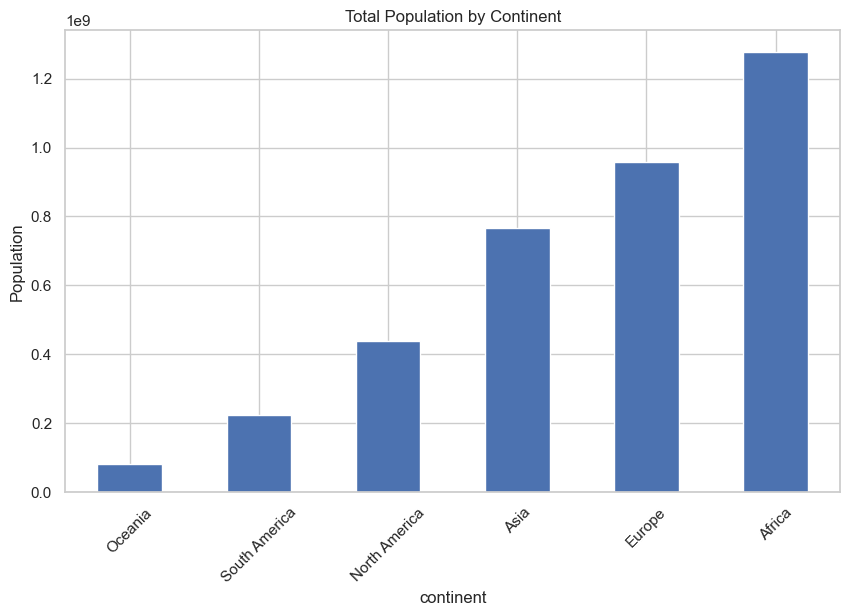

In [725]:
plt.figure(figsize=(10,6))
df_final_clean.groupby("continent")["population_csv"].sum().sort_values().plot(kind="bar")
plt.title("Total Population by Continent")
plt.ylabel("Population")
plt.xticks(rotation=45)
plt.show()


## Population vs Area

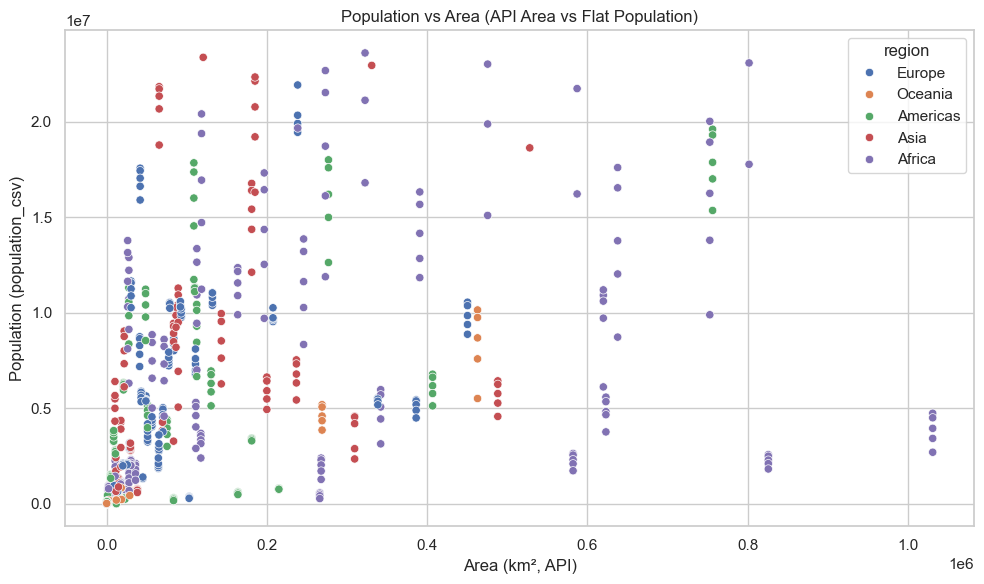

In [716]:
plot2 = df_final.dropna(subset=["area", "population_csv"]).copy()

plt.figure()
sns.scatterplot(
    data=plot2,
    x="area",
    y="population_csv",
    hue="region"
)
plt.title("Population vs Area (API Area vs Flat Population)")
plt.xlabel("Area (km², API)")
plt.ylabel("Population (population_csv)")
plt.tight_layout()
plt.show()


### Growth Rate vs Population Density

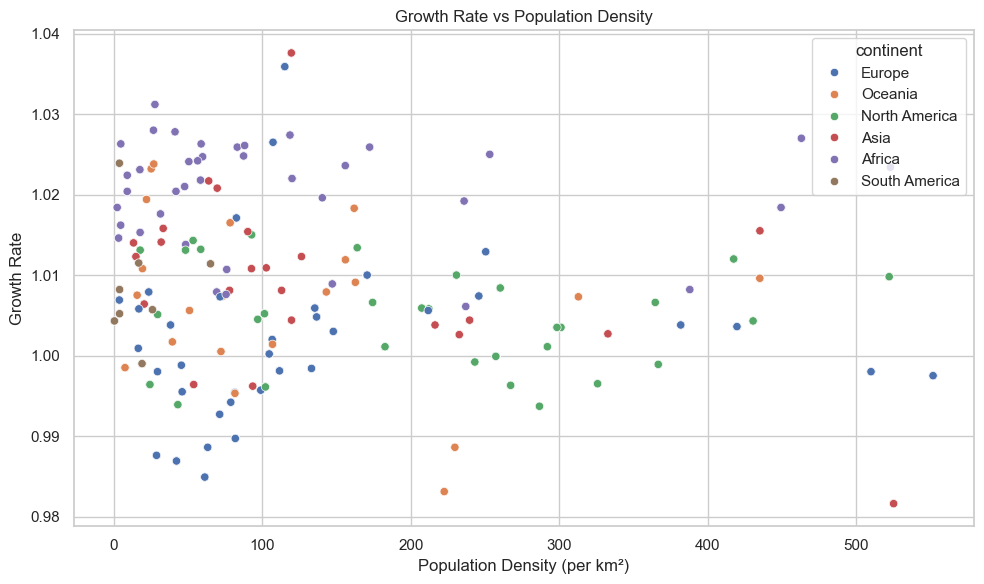

In [719]:
plot5 = df_final.dropna(subset=["density_per_km2", "growth_rate"]).copy()

plt.figure()
sns.scatterplot(
    data=plot5,
    x="density_per_km2",
    y="growth_rate",
    hue="continent"
)
plt.title("Growth Rate vs Population Density")
plt.xlabel("Population Density (per km²)")
plt.ylabel("Growth Rate")
plt.tight_layout()
plt.show()


### Population Vs Population Density

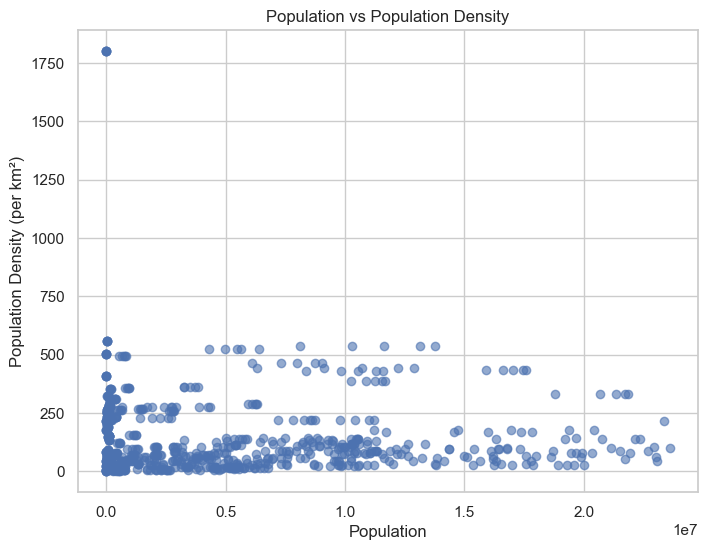

In [720]:


plt.figure(figsize=(8,6))
plt.scatter(df_final_clean["population_csv"], df_final_clean["population_density"], alpha=0.6)

plt.xlabel("Population")
plt.ylabel("Population Density (per km²)")
plt.title("Population vs Population Density")
plt.grid(True)
plt.show()


### Median Age Vs Fertility rate

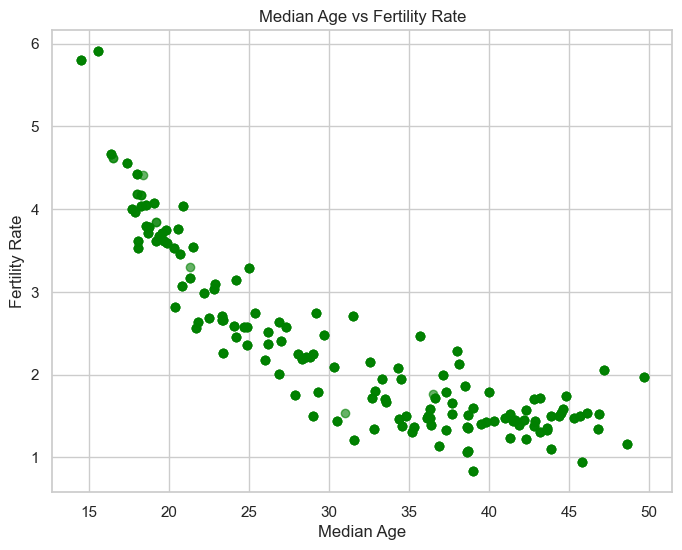

In [721]:
plt.figure(figsize=(8,6))
plt.scatter(df_final_clean["median_age"], df_final_clean["fert_rate"], alpha=0.6, color="green")

plt.xlabel("Median Age")
plt.ylabel("Fertility Rate")
plt.title("Median Age vs Fertility Rate")
plt.grid(True)
plt.show()


## Population by Countries

In [722]:
pop_by_country = (
    df_api[["country_name", "population"]]
    .dropna()
    .groupby("country_name", as_index=False)
    .sum()
)


In [723]:
top_countries = pop_by_country.sort_values("population", ascending=False).head(20)


<Figure size 1200x800 with 0 Axes>

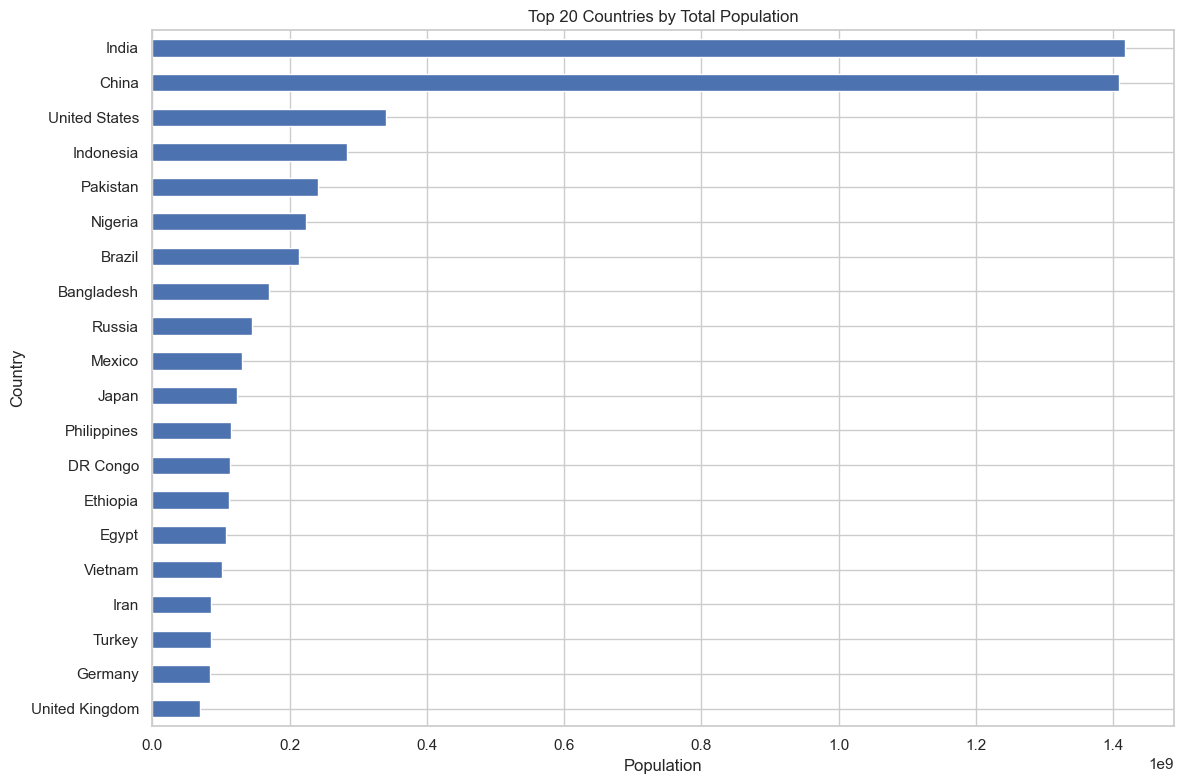

In [724]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
top_countries.plot(
    kind="barh",
    x="country_name",
    y="population",
    legend=False,
    figsize=(12, 8)
)

plt.title("Top 20 Countries by Total Population")
plt.xlabel("Population")
plt.ylabel("Country")
plt.gca().invert_yaxis()   # largest at top
plt.tight_layout()
plt.show()
